# 🛒 Online Shoppers Purchasing Intention — Revenue Prediction

**Tujuan:** Memprediksi apakah sesi kunjungan pengunjung website akan menghasilkan pembelian (`Revenue = 1`) atau tidak (`Revenue = 0`).

**Dataset:**
- `train.csv` — 8.631 baris, 21 kolom (termasuk target `Revenue`)
- `test.csv` — 3.699 baris, 21 kolom (tanpa target)
- `sample_submission.csv` — format submisi

**Pipeline:**
1. Import & Load Data
2. Exploratory Data Analysis (EDA)
3. Preprocessing
4. Feature Engineering
5. Modeling (Multiple Classifiers)
6. Evaluasi & Seleksi Model Terbaik
7. Prediksi & Export ke Excel


## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              ExtraTreesClassifier)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import openpyxl

# Plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

print("✅ Semua library berhasil diimport")


✅ Semua library berhasil diimport


## 2. Load Data

In [2]:
train = pd.read_csv('data/train.csv')
test  = pd.read_csv('data/test.csv')
sub   = pd.read_csv('data/sample_submission.csv')

print(f"Train  : {train.shape[0]:,} baris × {train.shape[1]} kolom")
print(f"Test   : {test.shape[0]:,} baris × {test.shape[1]} kolom")
print(f"Sample : {sub.shape}")
train.head()


Train  : 8,631 baris × 21 kolom
Test   : 3,699 baris × 21 kolom
Sample : (3699, 2)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,PageLoadTime,AvgTimePerPage,VisitorCohort,Revenue
0,4,45.40,0,0.0,14,339.000000,0.000000,0.010526,0.0,0.0,...,2,2,1,5,New_Visitor,False,-0.605680,33.148997,Alpha,0
1,1,40.25,0,0.0,19,501.766667,0.000000,0.010526,0.0,0.0,...,2,2,1,4,Returning_Visitor,False,-0.950063,31.293959,Charlie,0
2,0,0.00,0,0.0,13,244.166667,0.000000,0.030769,0.0,0.0,...,2,5,3,3,Returning_Visitor,False,0.429618,21.929662,Foxtrot,0
3,6,62.75,0,0.0,46,1098.524802,0.007083,0.016530,0.0,0.0,...,1,1,4,8,Returning_Visitor,False,-0.114951,37.724086,Hotel,0
4,0,0.00,0,0.0,2,19.000000,0.000000,0.100000,0.0,0.0,...,2,2,3,11,Returning_Visitor,True,1.088951,-5.452023,India,0


## 3. Exploratory Data Analysis (EDA)

In [3]:
# Info dasar
train.info()


<class 'pandas.DataFrame'>
RangeIndex: 8631 entries, 0 to 8630
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           8631 non-null   int64  
 1   Administrative_Duration  8631 non-null   float64
 2   Informational            8631 non-null   int64  
 3   Informational_Duration   8631 non-null   float64
 4   ProductRelated           8631 non-null   int64  
 5   ProductRelated_Duration  8631 non-null   float64
 6   BounceRates              8631 non-null   float64
 7   ExitRates                8631 non-null   float64
 8   PageValues               8631 non-null   float64
 9   SpecialDay               8631 non-null   float64
 10  Month                    8631 non-null   str    
 11  OperatingSystems         8631 non-null   int64  
 12  Browser                  8631 non-null   int64  
 13  Region                   8631 non-null   int64  
 14  TrafficType              8631 non-n

In [4]:
# Statistik deskriptif
train.describe().T.style.background_gradient(cmap='Blues')


,count,mean,std,min,25%,50%,75%,max
Administrative,8631.000000,2.315491,3.315156,0.000000,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,8631.000000,81.072768,179.645767,0.000000,0.000000,8.000000,92.750000,3398.750000
Informational,8631.000000,0.503418,1.275023,0.000000,0.000000,0.000000,0.000000,24.000000
Informational_Duration,8631.000000,34.617488,142.318157,0.000000,0.000000,0.000000,0.000000,2549.375000
ProductRelated,8631.000000,31.242730,43.190503,0.000000,7.000000,18.000000,37.000000,705.000000
ProductRelated_Duration,8631.000000,1177.572864,1904.559145,0.000000,183.000000,596.083333,1462.246229,63973.522230
BounceRates,8631.000000,0.022045,0.048490,0.000000,0.000000,0.002899,0.016667,0.200000
ExitRates,8631.000000,0.043043,0.048633,0.000000,0.014286,0.025012,0.050000,0.200000
PageValues,8631.000000,5.963568,18.630757,0.000000,0.000000,0.000000,0.000000,361.763742
SpecialDay,8631.000000,0.062843,0.201038,0.000000,0.000000,0.000000,0.000000,1.000000


In [5]:
# Missing values
missing = train.isnull().sum()
print("Missing values per kolom:")
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing values ✅")


Missing values per kolom:
Tidak ada missing values ✅


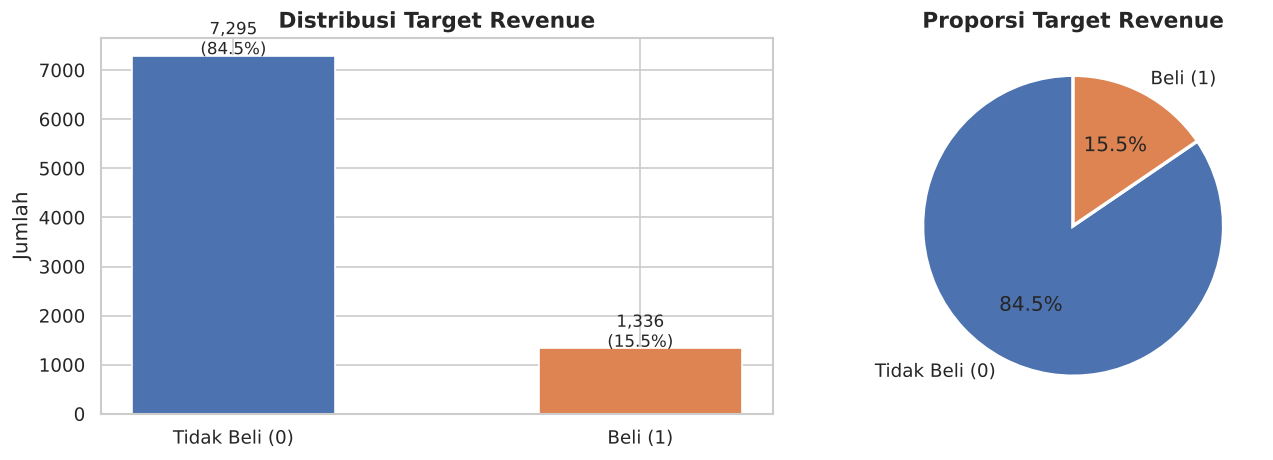


Class imbalance ratio: 5.46:1 (Tidak Beli : Beli)


In [6]:
# Distribusi Target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = train['Revenue'].value_counts()
labels = ['Tidak Beli (0)', 'Beli (1)']
colors = ['#4C72B0', '#DD8452']

axes[0].bar(labels, counts.values, color=colors, width=0.5, edgecolor='white')
axes[0].set_title('Distribusi Target Revenue', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Jumlah')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, f'{v:,}\n({v/len(train)*100:.1f}%)', ha='center', fontsize=10)

axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%', colors=colors,
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporsi Target Revenue', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('images/eda_target.png', dpi=120, bbox_inches='tight')
plt.show()
print(f"\nClass imbalance ratio: {counts[0]/counts[1]:.2f}:1 (Tidak Beli : Beli)")


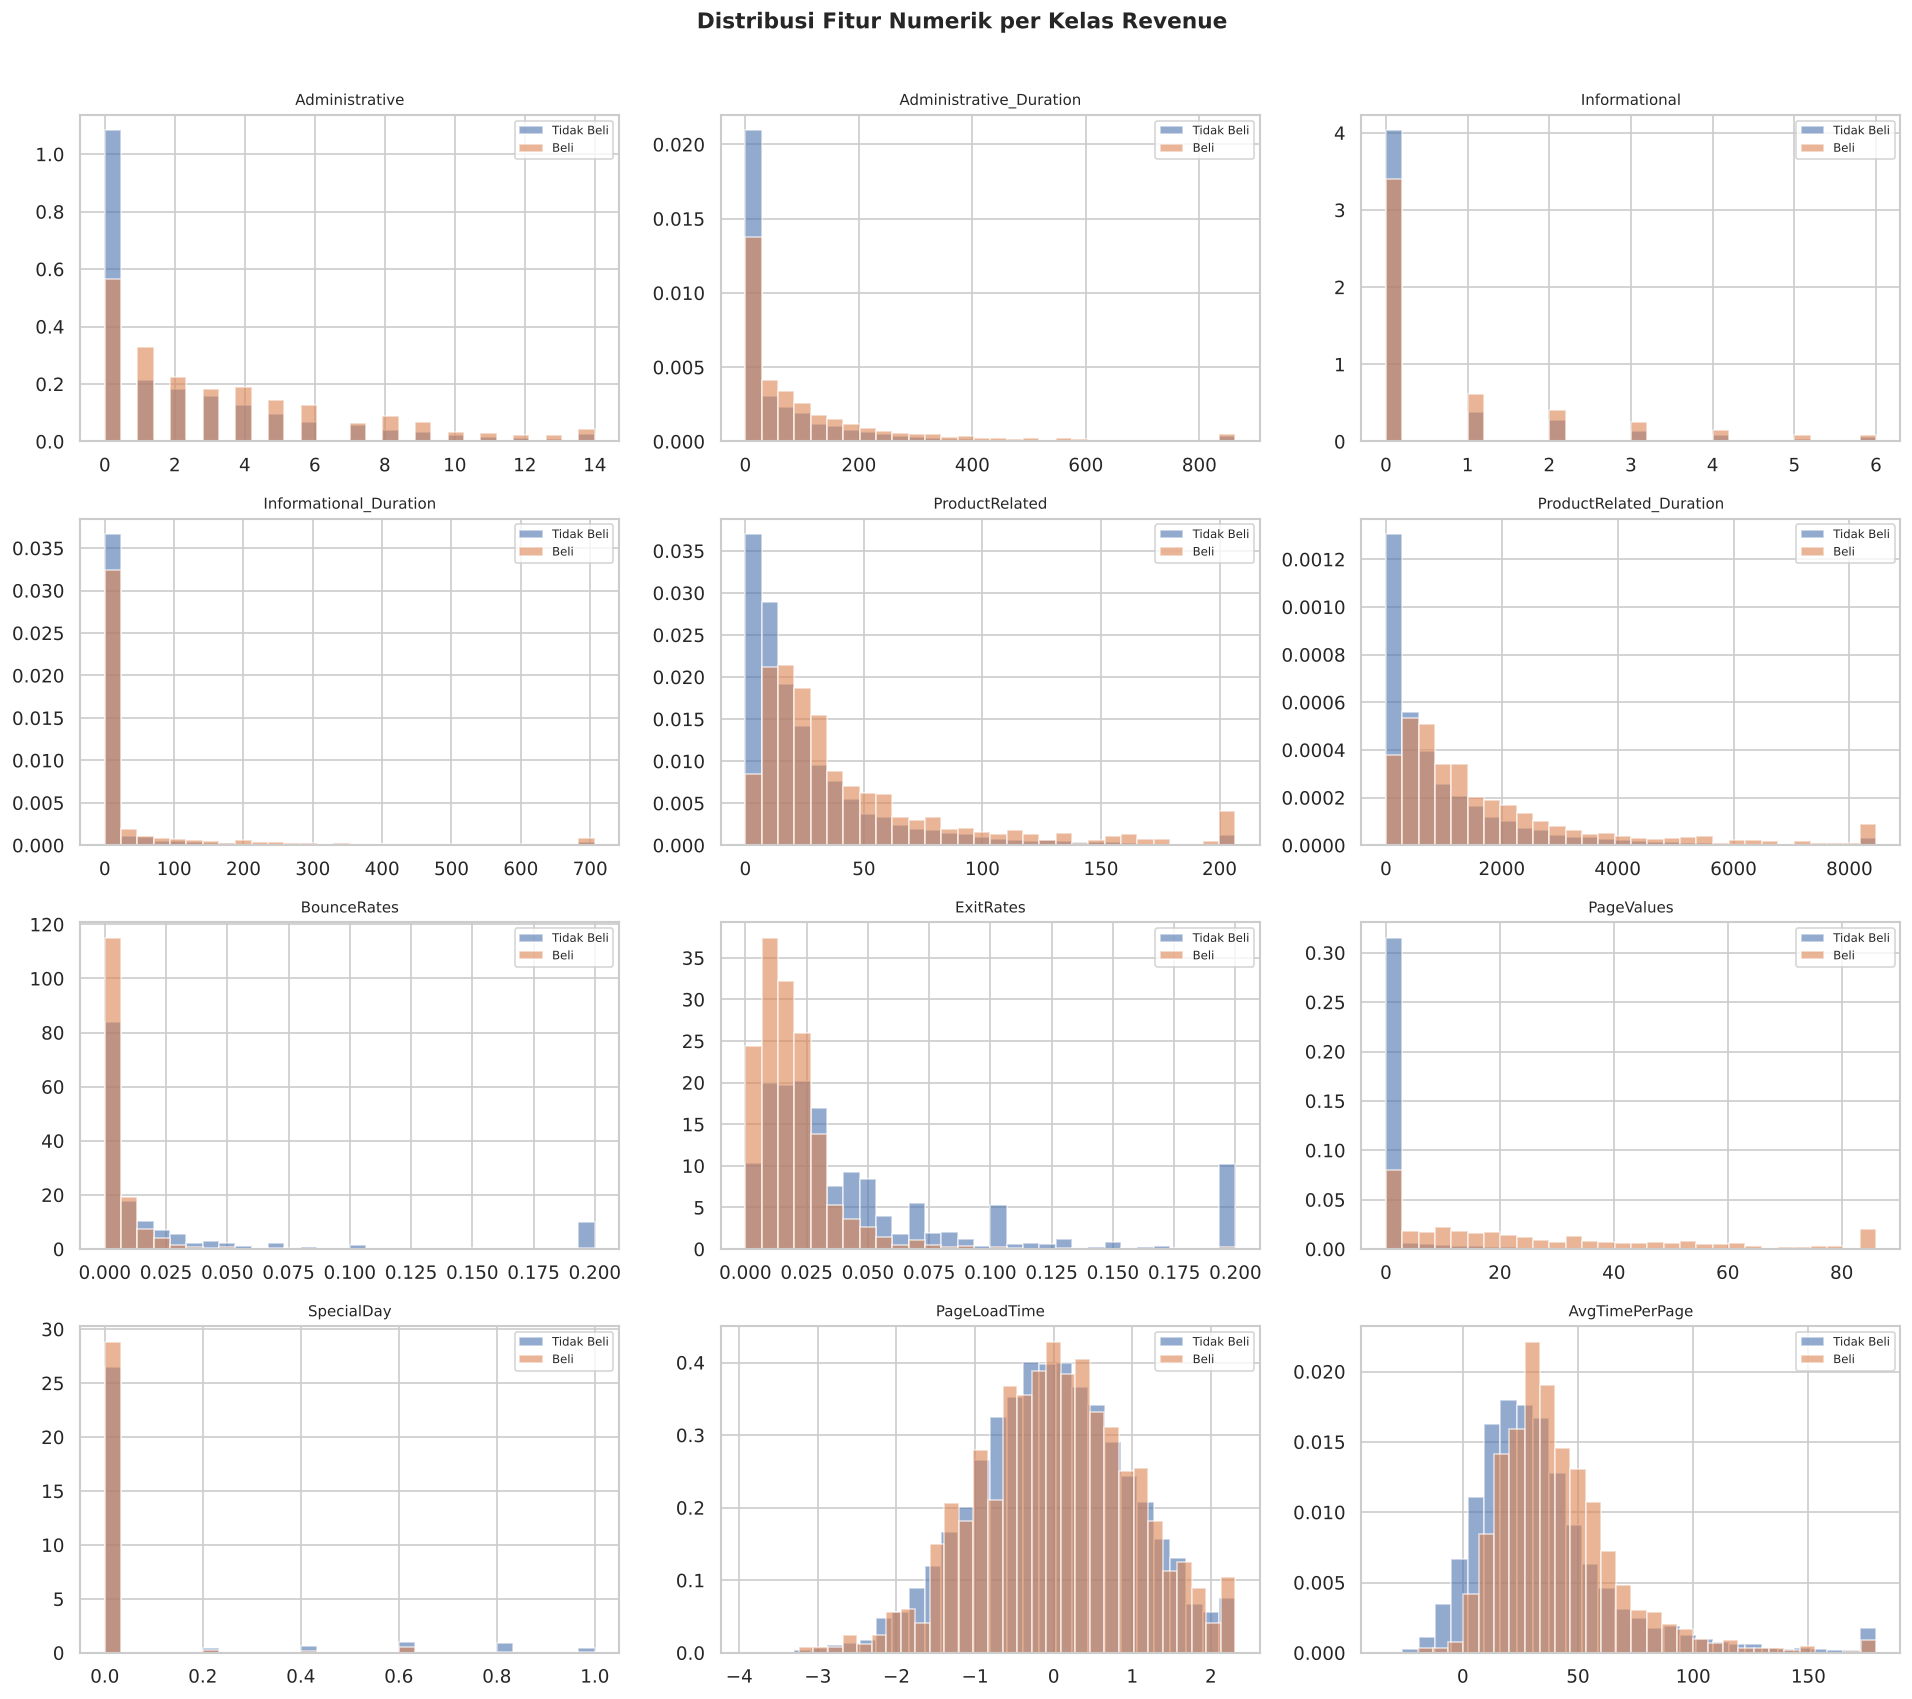

In [7]:
# Distribusi fitur numerik
num_cols = ['Administrative', 'Administrative_Duration', 'Informational',
            'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
            'PageLoadTime', 'AvgTimePerPage']

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    for rev, color, label in [(0, '#4C72B0', 'Tidak Beli'), (1, '#DD8452', 'Beli')]:
        axes[i].hist(train[train['Revenue'] == rev][col].clip(upper=train[col].quantile(0.99)),
                     bins=30, alpha=0.6, color=color, label=label, density=True)
    axes[i].set_title(col, fontsize=9)
    axes[i].legend(fontsize=7)

plt.suptitle('Distribusi Fitur Numerik per Kelas Revenue', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('images/eda_numeric.png', dpi=120, bbox_inches='tight')
plt.show()


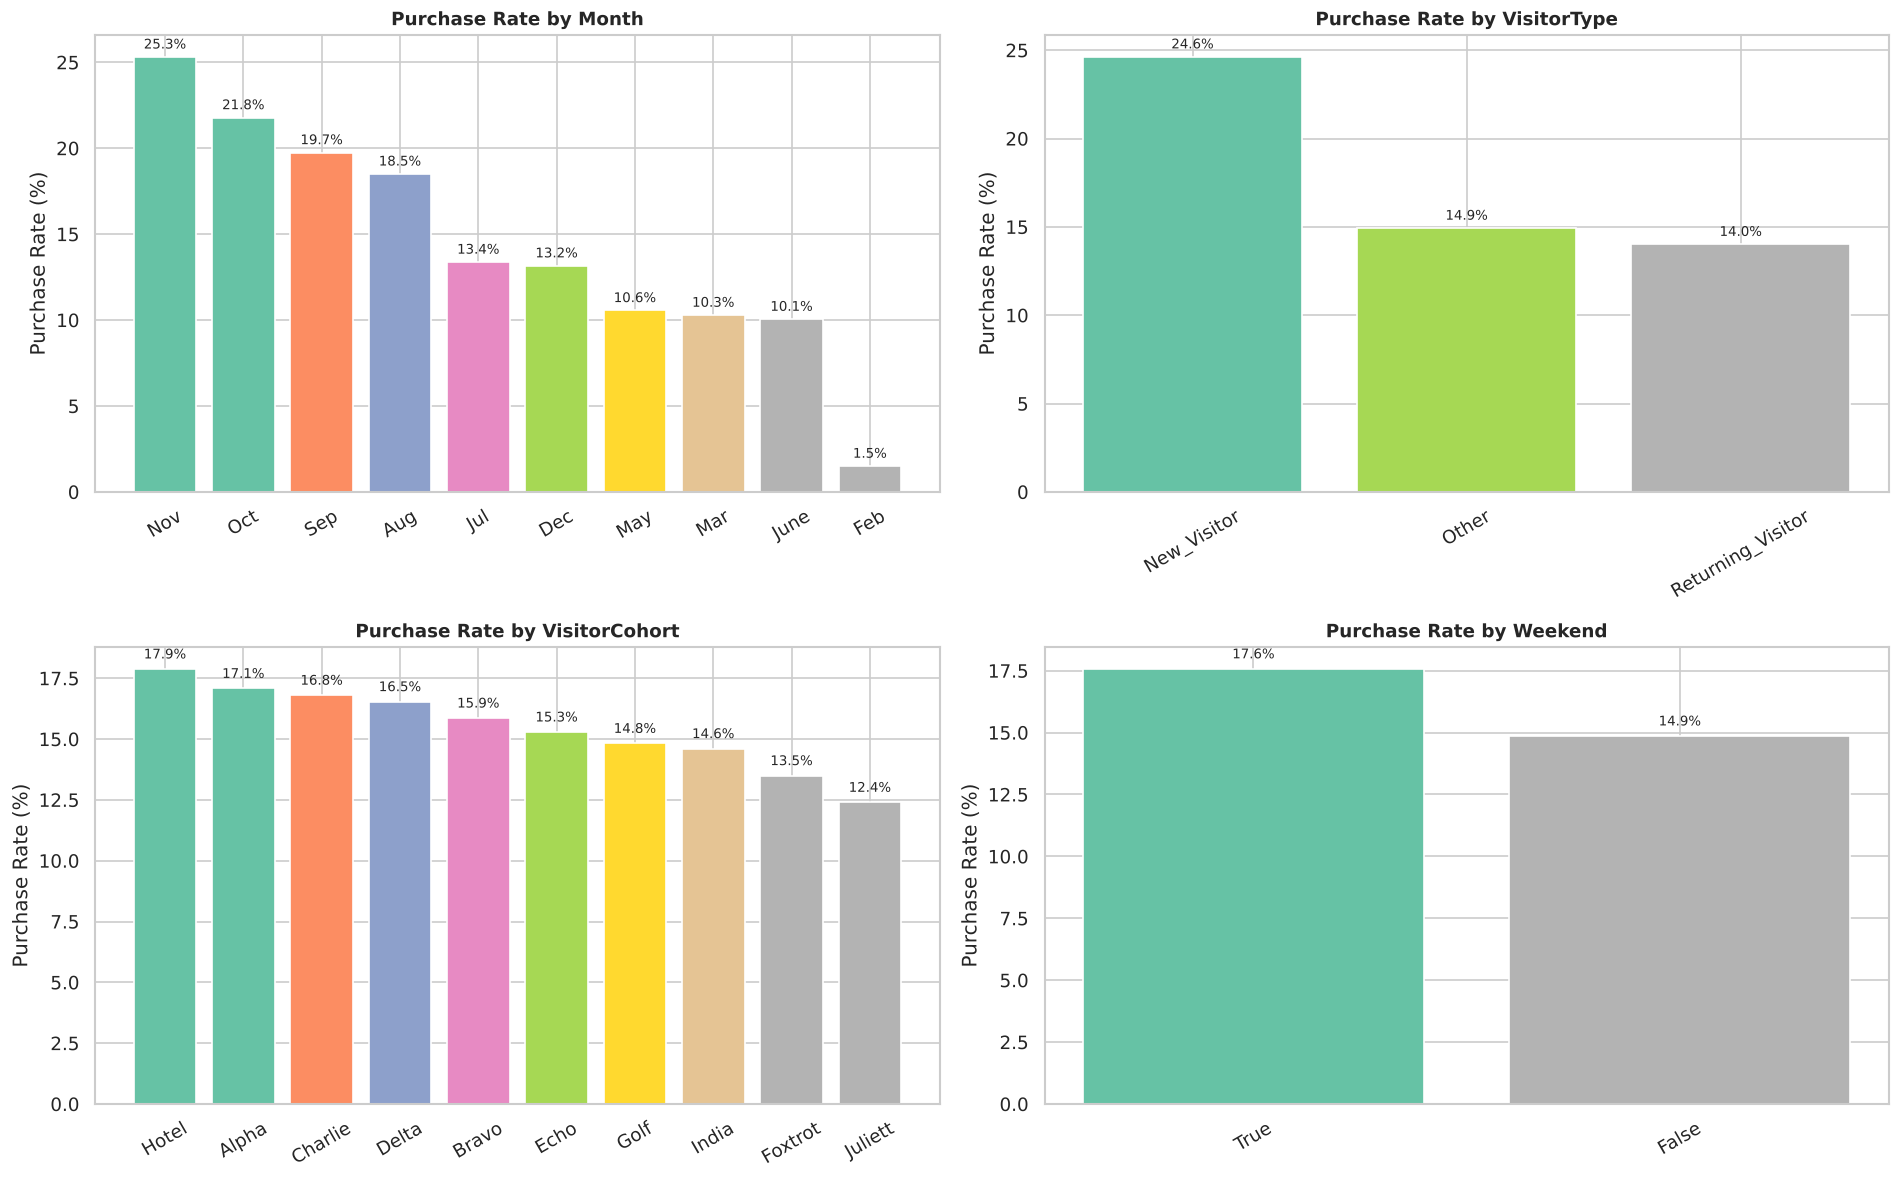

In [8]:
# Analisis fitur kategorikal
cat_cols = ['Month', 'VisitorType', 'VisitorCohort', 'Weekend']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    pivot = train.groupby(col)['Revenue'].agg(['sum', 'count'])
    pivot['rate'] = pivot['sum'] / pivot['count'] * 100
    pivot = pivot.sort_values('rate', ascending=False)
    
    bars = axes[i].bar(pivot.index.astype(str), pivot['rate'],
                       color=plt.cm.Set2(np.linspace(0, 1, len(pivot))),
                       edgecolor='white')
    axes[i].set_title(f'Purchase Rate by {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Purchase Rate (%)')
    axes[i].tick_params(axis='x', rotation=30)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                     ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('images/eda_categorical.png', dpi=120, bbox_inches='tight')
plt.show()


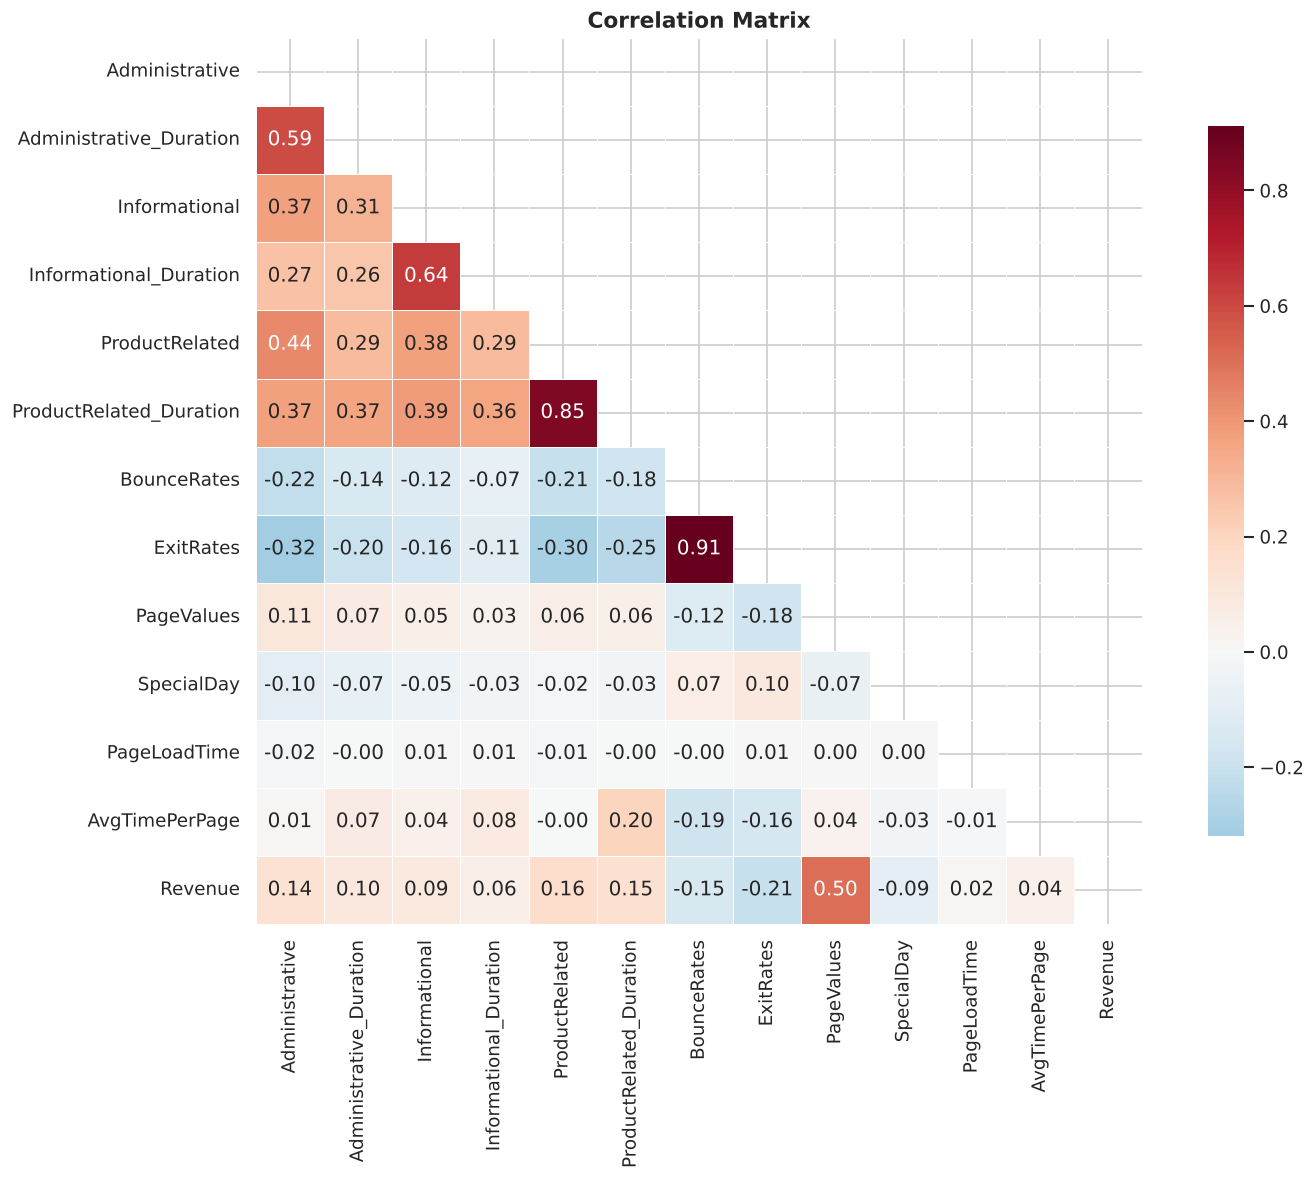

In [9]:
# Korelasi antar fitur numerik
corr_matrix = train[num_cols + ['Revenue']].corr()

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('images/eda_correlation.png', dpi=120, bbox_inches='tight')
plt.show()


## 4. Preprocessing & Feature Engineering

In [10]:
# Pisahkan target
X = train.drop(columns=['Revenue'])
y = train['Revenue']
X_test = test.drop(columns=['Id'])
test_ids = test['Id']

print("Shape X train:", X.shape)
print("Shape X test :", X_test.shape)


Shape X train: (8631, 20)
Shape X test : (3699, 20)


In [11]:
def preprocess(df, is_train=True, encoders=None):
    df = df.copy()
    
    # ── Feature Engineering ──────────────────────────────────────────────
    # Total halaman yang dikunjungi
    df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
    # Total durasi
    df['Total_Duration'] = (df['Administrative_Duration'] +
                            df['Informational_Duration'] +
                            df['ProductRelated_Duration'])
    # Rasio durasi per halaman
    df['Duration_Per_Page'] = df['Total_Duration'] / (df['Total_Pages'] + 1)
    # Ratio product related
    df['ProductRelated_Ratio'] = df['ProductRelated'] / (df['Total_Pages'] + 1)
    # High bounce flag
    df['HighBounce'] = (df['BounceRates'] > df['BounceRates'].quantile(0.75)).astype(int)
    # Has Page Value flag
    df['HasPageValue'] = (df['PageValues'] > 0).astype(int)
    # Log transforms (skewed features)
    for col in ['PageValues', 'ProductRelated_Duration', 'Total_Duration',
                'Administrative_Duration', 'Informational_Duration']:
        df[f'log_{col}'] = np.log1p(df[col])
    
    # ── Encoding ─────────────────────────────────────────────────────────
    cat_cols = ['Month', 'VisitorType', 'VisitorCohort']
    
    if is_train:
        encoders = {}
        for col in cat_cols:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col].astype(str))
            encoders[col] = le
    else:
        for col in cat_cols:
            le = encoders[col]
            df[col] = df[col].astype(str).map(
                lambda x, le=le: le.transform([x])[0] if x in le.classes_ else -1
            )
    
    # Boolean
    df['Weekend'] = df['Weekend'].astype(int)
    
    return df, encoders

X_proc, encoders = preprocess(X, is_train=True)
X_test_proc, _ = preprocess(X_test, is_train=False, encoders=encoders)

print("Shape setelah preprocessing:")
print(f"  X train: {X_proc.shape}")
print(f"  X test : {X_test_proc.shape}")
print(f"\nFitur baru: {X_proc.shape[1] - X.shape[1]} fitur ditambahkan")


Shape setelah preprocessing:
  X train: (8631, 31)
  X test : (3699, 31)

Fitur baru: 11 fitur ditambahkan


In [12]:
# Scaling
scaler = StandardScaler()
feature_cols = X_proc.columns.tolist()

X_scaled = scaler.fit_transform(X_proc)
X_test_scaled = scaler.transform(X_test_proc)

print("✅ Scaling selesai")
print(f"Total fitur: {len(feature_cols)}")


✅ Scaling selesai
Total fitur: 31


## 5. Modeling

In [13]:
# Split train/validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train  : {X_tr.shape[0]:,} baris | Beli={y_tr.sum():,} ({y_tr.mean()*100:.1f}%)")
print(f"Val    : {X_val.shape[0]:,} baris | Beli={y_val.sum():,} ({y_val.mean()*100:.1f}%)")


Train  : 6,904 baris | Beli=1,069 (15.5%)
Val    : 1,727 baris | Beli=267 (15.5%)


In [14]:
# Definisi model
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Decision Tree'      : DecisionTreeClassifier(max_depth=8, random_state=42, class_weight='balanced'),
    'Random Forest'      : RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42,
                                                   class_weight='balanced', n_jobs=-1),
    'Extra Trees'        : ExtraTreesClassifier(n_estimators=200, max_depth=10, random_state=42,
                                                class_weight='balanced', n_jobs=-1),
    'Gradient Boosting'  : GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                                       max_depth=5, random_state=42),
    'XGBoost'            : XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                                         scale_pos_weight=y_tr.value_counts()[0]/y_tr.value_counts()[1],
                                         eval_metric='auc', random_state=42, n_jobs=-1, verbosity=0),
    'LightGBM'           : LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                                           class_weight='balanced', random_state=42,
                                           n_jobs=-1, verbose=-1),
}

print(f"Total model yang akan dilatih: {len(models)}")


Total model yang akan dilatih: 7


In [15]:
# Training & Evaluasi semua model
results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"Training {name}...", end=' ')
    model.fit(X_tr, y_tr)
    
    # Prediksi probabilitas
    y_pred_proba = model.predict_proba(X_val)[:, 1]
    y_pred = model.predict(X_val)
    
    # Cross-validation AUC
    cv_auc = cross_val_score(model, X_scaled, y, cv=skf, scoring='roc_auc', n_jobs=-1).mean()
    val_auc = roc_auc_score(y_val, y_pred_proba)
    
    report = classification_report(y_val, y_pred, output_dict=True)
    
    results[name] = {
        'model'     : model,
        'val_auc'   : val_auc,
        'cv_auc'    : cv_auc,
        'proba'     : y_pred_proba,
        'pred'      : y_pred,
        'precision' : report['1']['precision'],
        'recall'    : report['1']['recall'],
        'f1'        : report['1']['f1-score'],
    }
    print(f"✅  Val AUC={val_auc:.4f} | CV AUC={cv_auc:.4f}")


Training Logistic Regression... 

✅  Val AUC=0.9011 | CV AUC=0.9092
Training Decision Tree... 

✅  Val AUC=0.8587 | CV AUC=0.8588
Training Random Forest... 

✅  Val AUC=0.9229 | CV AUC=0.9284
Training Extra Trees... 

✅  Val AUC=0.9178 | CV AUC=0.9222
Training Gradient Boosting... 

✅  Val AUC=0.9254 | CV AUC=0.9291
Training XGBoost... 

✅  Val AUC=0.9191 | CV AUC=0.9252
Training LightGBM... 

✅  Val AUC=0.9213 | CV AUC=0.9249


In [16]:
# Ringkasan perbandingan model
results_df = pd.DataFrame([
    {
        'Model'    : name,
        'Val AUC'  : r['val_auc'],
        'CV AUC'   : r['cv_auc'],
        'Precision': r['precision'],
        'Recall'   : r['recall'],
        'F1-Score' : r['f1'],
    }
    for name, r in results.items()
]).sort_values('Val AUC', ascending=False).reset_index(drop=True)

results_df.index = results_df.index + 1
results_df.style.background_gradient(subset=['Val AUC', 'CV AUC', 'F1-Score'], cmap='Greens')


,Model,Val AUC,CV AUC,Precision,Recall,F1-Score
1,Gradient Boosting,0.925443,0.929126,0.714286,0.599251,0.651731
2,Random Forest,0.922903,0.928424,0.587571,0.779026,0.669887
3,LightGBM,0.921325,0.924878,0.603077,0.734082,0.662162
4,XGBoost,0.919055,0.925152,0.629870,0.726592,0.674783
5,Extra Trees,0.917790,0.922152,0.600567,0.794007,0.683871
6,Logistic Regression,0.901126,0.909180,0.585561,0.820225,0.683307
7,Decision Tree,0.858749,0.858787,0.529716,0.767790,0.626911


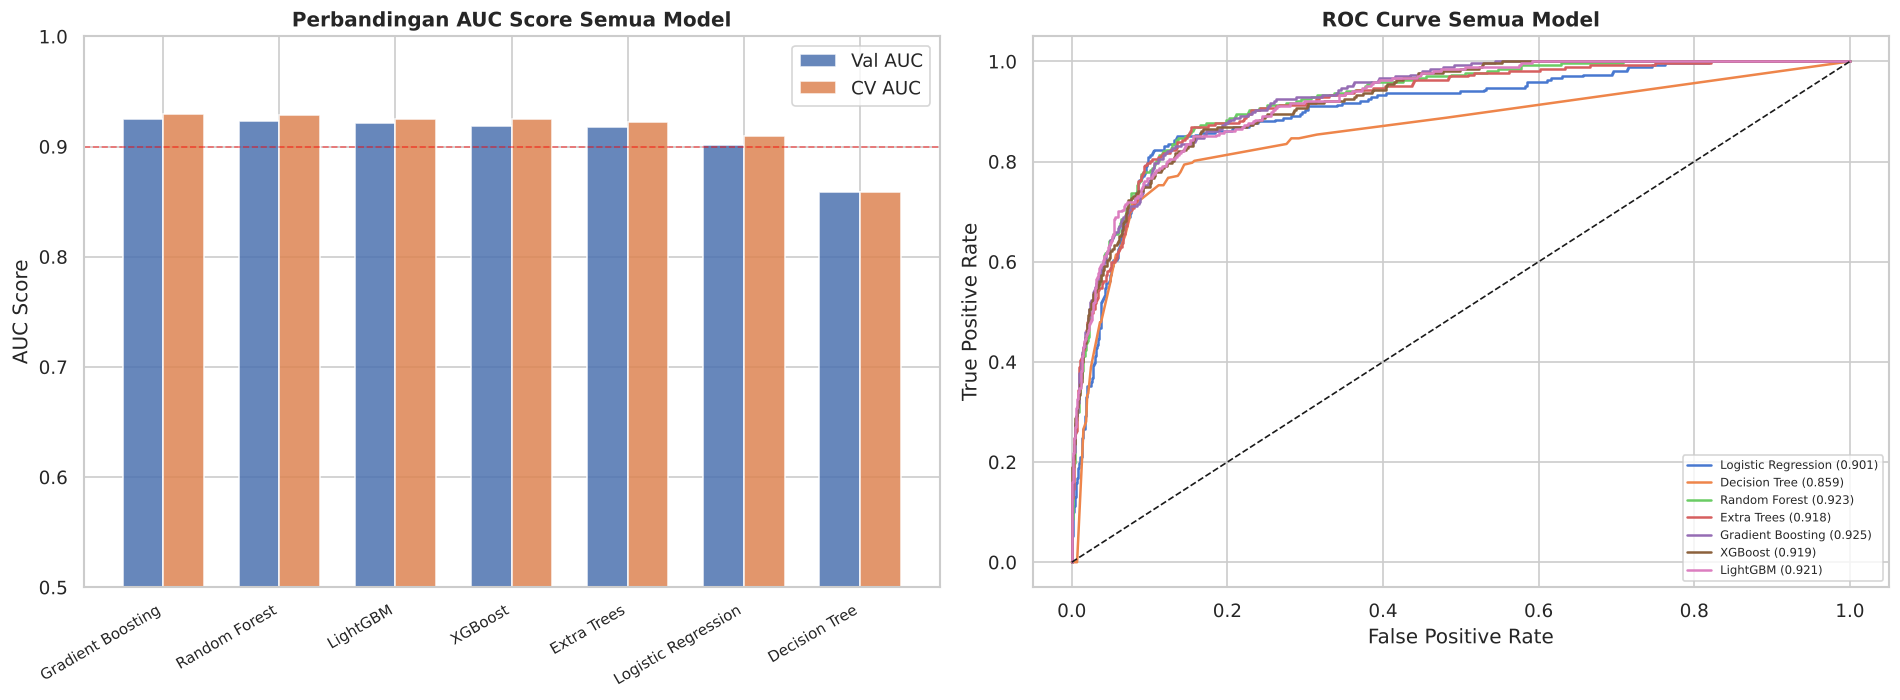

In [17]:
# Visualisasi perbandingan model
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart AUC
model_names = results_df['Model'].tolist()
val_aucs = results_df['Val AUC'].tolist()
cv_aucs  = results_df['CV AUC'].tolist()

x = np.arange(len(model_names))
w = 0.35

axes[0].bar(x - w/2, val_aucs, w, label='Val AUC', color='#4C72B0', alpha=0.85)
axes[0].bar(x + w/2, cv_aucs,  w, label='CV AUC',  color='#DD8452', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=30, ha='right', fontsize=9)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_ylabel('AUC Score')
axes[0].set_title('Perbandingan AUC Score Semua Model', fontweight='bold')
axes[0].legend()
axes[0].axhline(0.9, color='red', ls='--', lw=1, alpha=0.5, label='AUC=0.9')

# ROC Curves
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_val, r['proba'])
    axes[1].plot(fpr, tpr, lw=1.5, label=f"{name} ({r['val_auc']:.3f})")

axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve Semua Model', fontweight='bold')
axes[1].legend(fontsize=7, loc='lower right')

plt.tight_layout()
plt.savefig('images/model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


In [18]:
# Pilih model terbaik
best_name = results_df.iloc[0]['Model']
best_model = results[best_name]['model']
print(f"🏆 Model Terbaik: {best_name}")
print(f"   Val AUC : {results[best_name]['val_auc']:.4f}")
print(f"   CV AUC  : {results[best_name]['cv_auc']:.4f}")
print(f"   F1-Score: {results[best_name]['f1']:.4f}")


🏆 Model Terbaik: Gradient Boosting
   Val AUC : 0.9254
   CV AUC  : 0.9291
   F1-Score: 0.6517


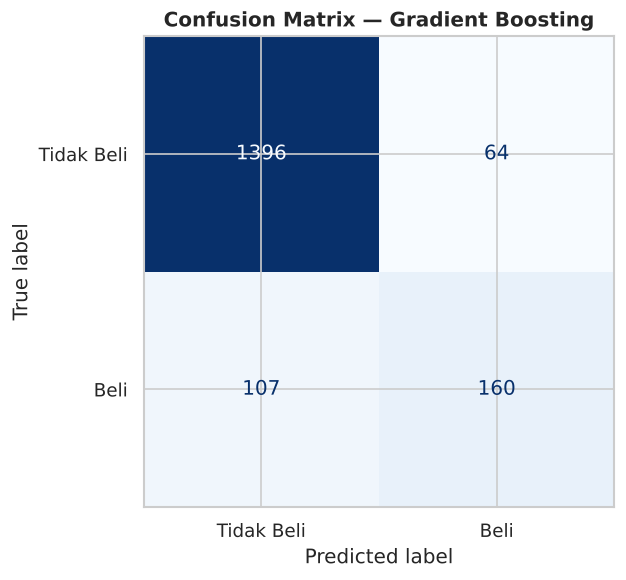


Classification Report:
              precision    recall  f1-score   support

  Tidak Beli       0.93      0.96      0.94      1460
        Beli       0.71      0.60      0.65       267

    accuracy                           0.90      1727
   macro avg       0.82      0.78      0.80      1727
weighted avg       0.90      0.90      0.90      1727



In [19]:
# Confusion Matrix model terbaik
cm = confusion_matrix(y_val, results[best_name]['pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Tidak Beli', 'Beli'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — {best_name}', fontweight='bold')
plt.tight_layout()
plt.savefig('images/confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

print("\nClassification Report:")
print(classification_report(y_val, results[best_name]['pred'],
                            target_names=['Tidak Beli', 'Beli']))


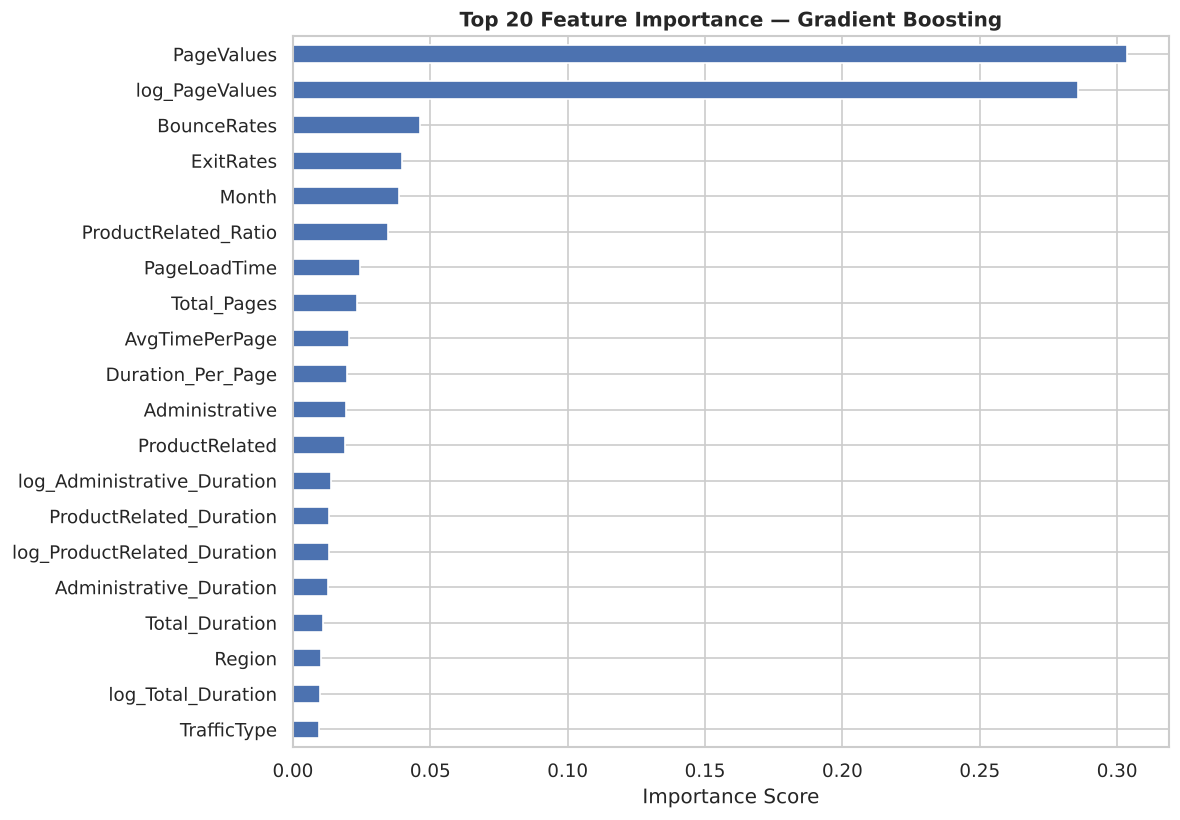

In [20]:
# Feature Importance (jika tersedia)
if hasattr(best_model, 'feature_importances_'):
    fi = pd.Series(best_model.feature_importances_, index=feature_cols)
    fi = fi.sort_values(ascending=False).head(20)
    
    plt.figure(figsize=(10, 7))
    fi.sort_values().plot(kind='barh', color='#4C72B0', edgecolor='white')
    plt.title(f'Top 20 Feature Importance — {best_name}', fontweight='bold')
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.savefig('images/feature_importance.png', dpi=120, bbox_inches='tight')
    plt.show()


## 6. Prediksi & Export ke Excel

In [21]:
# Retrain model terbaik pada seluruh data train
print(f"Retraining {best_name} pada seluruh data training...")
best_model.fit(X_scaled, y)
print("✅ Selesai")

# Prediksi probabilitas pada test set
y_test_proba = best_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred  = best_model.predict(X_test_scaled)

print(f"\nPrediksi test set:")
print(f"  Beli     : {y_test_pred.sum():,} ({y_test_pred.mean()*100:.1f}%)")
print(f"  Tidak Beli: {(1-y_test_pred).sum():,} ({(1-y_test_pred).mean()*100:.1f}%)")
print(f"  Prob rata-rata: {y_test_proba.mean():.4f}")


Retraining Gradient Boosting pada seluruh data training...


✅ Selesai

Prediksi test set:
  Beli     : 480 (13.0%)
  Tidak Beli: 3,219 (87.0%)
  Prob rata-rata: 0.1529


In [22]:
# Buat submission DataFrame
submission = pd.DataFrame({
    'Id'     : test_ids.values,
    'Revenue': y_test_proba,
})
print("Preview submission:")
print(submission.head(10))
print(f"\nShape: {submission.shape}")


Preview submission:
   Id   Revenue
0   1  0.017008
1   2  0.003696
2   3  0.547944
3   4  0.061564
4   5  0.660485
5   6  0.011042
6   7  0.004887
7   8  0.009748
8   9  0.063665
9  10  0.003126

Shape: (3699, 2)


In [23]:
# ──────────────────────────────────────────────────────────────────────────────
# EXPORT KE EXCEL (multi-sheet)
# ──────────────────────────────────────────────────────────────────────────────
output_path = 'outputs/submission_revenue_prediction.xlsx'

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    
    # Sheet 1: Submission (format kompetisi)
    submission.to_excel(writer, sheet_name='Submission', index=False)
    
    # Sheet 2: Submission + Label Binary
    sub_extended = submission.copy()
    sub_extended['Revenue_Label'] = y_test_pred
    sub_extended['Kategori']      = sub_extended['Revenue_Label'].map({1: 'Beli', 0: 'Tidak Beli'})
    sub_extended.to_excel(writer, sheet_name='Prediksi_Detail', index=False)
    
    # Sheet 3: Model Comparison
    results_df.to_excel(writer, sheet_name='Model_Comparison', index=False)
    
    # Sheet 4: Train Data + Prediksi
    train_pred_proba = best_model.predict_proba(X_scaled)[:, 1]
    train_result = train.copy()
    train_result['Pred_Proba'] = train_pred_proba
    train_result['Pred_Label'] = best_model.predict(X_scaled)
    train_result.to_excel(writer, sheet_name='Train_Predictions', index=False)
    
    # ── Styling ────────────────────────────────────────────────────────────
    wb = writer.book
    
    from openpyxl.styles import (PatternFill, Font, Alignment, Border, Side,
                                  GradientFill)
    from openpyxl.utils import get_column_letter
    from openpyxl.formatting.rule import ColorScaleRule, DataBarRule
    
    header_fill  = PatternFill('solid', fgColor='1F4E79')
    header_font  = Font(color='FFFFFF', bold=True, size=11)
    center_align = Alignment(horizontal='center', vertical='center')
    thin_border  = Border(
        left=Side(style='thin', color='BFBFBF'),
        right=Side(style='thin', color='BFBFBF'),
        top=Side(style='thin', color='BFBFBF'),
        bottom=Side(style='thin', color='BFBFBF'),
    )
    
    def style_sheet(ws, col_widths=None):
        # Header styling
        for cell in ws[1]:
            cell.fill      = header_fill
            cell.font      = header_font
            cell.alignment = center_align
            cell.border    = thin_border
        # Data rows alternating color
        fills = [PatternFill('solid', fgColor='EBF3FB'),
                 PatternFill('solid', fgColor='FFFFFF')]
        for i, row in enumerate(ws.iter_rows(min_row=2)):
            for cell in row:
                cell.fill      = fills[i % 2]
                cell.alignment = Alignment(horizontal='center')
                cell.border    = thin_border
        # Column widths
        if col_widths:
            for col_letter, width in col_widths.items():
                ws.column_dimensions[col_letter].width = width
        else:
            for col in ws.columns:
                max_len = max(len(str(cell.value or '')) for cell in col) + 4
                ws.column_dimensions[col[0].column_letter].width = min(max_len, 30)
        # Freeze top row
        ws.freeze_panes = 'A2'
    
    # Style semua sheet
    for sheet_name in ['Submission', 'Prediksi_Detail', 'Model_Comparison']:
        style_sheet(wb[sheet_name])
    
    # Color scale pada kolom Revenue (Submission)
    ws_sub = wb['Submission']
    ws_sub.conditional_formatting.add(
        f'B2:B{len(submission)+1}',
        ColorScaleRule(start_type='min', start_color='FFC7CE',
                       mid_type='percentile', mid_value=50, mid_color='FFEB9C',
                       end_type='max', end_color='C6EFCE')
    )
    
    # Style Model Comparison — highlight baris terbaik
    ws_mc = wb['Model_Comparison']
    best_row_idx = results_df.index[0] + 2  # header=1, 1-indexed
    gold_fill = PatternFill('solid', fgColor='FFD700')
    for cell in ws_mc[best_row_idx]:
        cell.fill = gold_fill
        cell.font = Font(bold=True)
    
    # Color scale AUC columns
    ws_mc.conditional_formatting.add(
        f'B2:B{len(results_df)+1}',
        ColorScaleRule(start_type='min', start_color='FFC7CE',
                       end_type='max',   end_color='C6EFCE')
    )
    ws_mc.conditional_formatting.add(
        f'C2:C{len(results_df)+1}',
        ColorScaleRule(start_type='min', start_color='FFC7CE',
                       end_type='max',   end_color='C6EFCE')
    )

print(f"✅ File Excel berhasil disimpan: '{output_path}'")
print(f"\nSheet yang tersedia:")
print("  📋 Submission       — format submisi kompetisi (Id, Revenue probability)")
print("  📊 Prediksi_Detail  — detail prediksi + label biner + kategori")
print("  🏆 Model_Comparison — perbandingan semua model yang diuji")
print("  📁 Train_Predictions— data train + hasil prediksi model")


✅ File Excel berhasil disimpan: 'outputs/submission_revenue_prediction.xlsx'

Sheet yang tersedia:
  📋 Submission       — format submisi kompetisi (Id, Revenue probability)
  📊 Prediksi_Detail  — detail prediksi + label biner + kategori
  🏆 Model_Comparison — perbandingan semua model yang diuji
  📁 Train_Predictions— data train + hasil prediksi model


In [24]:
# Verifikasi output
print("=" * 50)
print("RINGKASAN AKHIR")
print("=" * 50)
print(f"Model terbaik    : {best_name}")
print(f"Val AUC          : {results[best_name]['val_auc']:.4f}")
print(f"CV AUC (5-fold)  : {results[best_name]['cv_auc']:.4f}")
print(f"F1-Score (class 1): {results[best_name]['f1']:.4f}")
print(f"\nTest predictions :")
print(f"  Total baris    : {len(submission):,}")
print(f"  Prediksi Beli  : {y_test_pred.sum():,} ({y_test_pred.mean()*100:.1f}%)")
print(f"  Prob rata-rata : {y_test_proba.mean():.4f}")
print(f"\nOutput file      : outputs/submission_revenue_prediction.xlsx")


RINGKASAN AKHIR
Model terbaik    : Gradient Boosting
Val AUC          : 0.9254
CV AUC (5-fold)  : 0.9291
F1-Score (class 1): 0.6517

Test predictions :
  Total baris    : 3,699
  Prediksi Beli  : 480 (13.0%)
  Prob rata-rata : 0.1529

Output file      : outputs/submission_revenue_prediction.xlsx
